<a href="https://colab.research.google.com/github/RaidahAhmed/NLP-GROUP-PROJECT-RAIDAH-AND-NAWE/blob/main/NLP_Group_Project_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Installing libraries, "-q" means "quiet" so it prints less.
!pip install -q datasets transformers scikit-learn evaluate accelerate gradio fastapi uvicorn pypdf sentence-transformers wordcloud

In [ ]:
#Importing necessary libraries

import re, os, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud
import torch                           # the engine that runs DistilBERT

from datasets import load_dataset, Dataset
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

import keras
from keras import layers, regularizers
from keras.callbacks import EarlyStopping

# Transformers (DistilBERT)
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, DataCollatorWithPadding, pipeline)

print("GPU available:", torch.cuda.is_available())   # should say True if you chose T4 GPU

GPU available: True


---
# Part 1 · Training the sentiment model

In [ ]:
#Loading the dataset
raw = load_dataset("stanfordnlp/imdb")
raw

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})

In [ ]:
#Turning the data into pandas tables.
train_full = raw["train"].to_pandas()
test_full = raw["test"].to_pandas()
print(train_full.shape, test_full.shape)   # display number of rows, columns
train_full.head()                          # display the first 5 rows

(25000, 2) (25000, 2)


,text,label
0,I rented I AM CURIOUS-YELLOW from my video sto...,0
1,"""I Am Curious: Yellow"" is a risible and preten...",0
2,If only to avoid making this type of film in t...,0
3,This film was probably inspired by Godard's Ma...,0
4,"Oh, brother...after hearing about this ridicul...",0


## 1.2 · Exploring the data

label
0    12500
1    12500
Name: count, dtype: int64


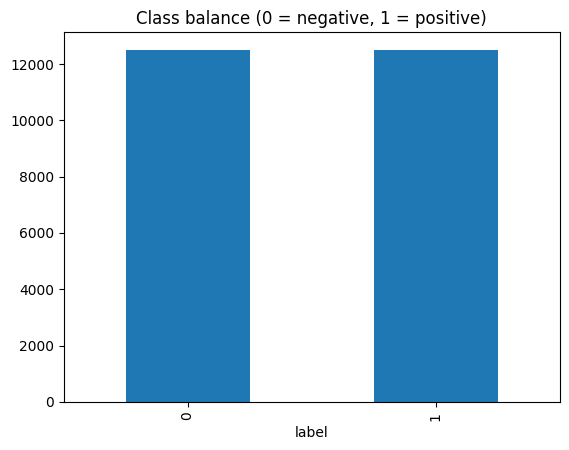

In [ ]:
# Counting how many positive and negative reviews we have.
print(train_full["label"].value_counts())
train_full["label"].value_counts().plot(kind="bar", title="Class balance (0 = negative, 1 = positive)")
plt.show()

count    25000.000000
mean       233.787200
std        173.733032
min         10.000000
25%        127.000000
50%        174.000000
75%        284.000000
max       2470.000000
Name: n_words, dtype: float64


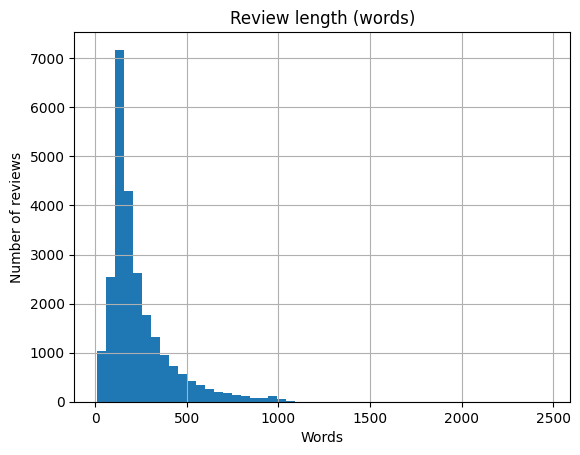

In [ ]:
#Measuring how long reviews are in words because transformers can only read a limited number of tokens, so long reviews get cut.
train_full["n_words"] = train_full["text"].str.split().str.len()
print(train_full["n_words"].describe())

train_full["n_words"].hist(bins=50)
plt.title("Review length (words)")
plt.xlabel("Words"); plt.ylabel("Number of reviews")
plt.show()

In [ ]:
# Reading 2 real negative and 2 real positive reviews to check for issues we must clean.
for label in [0, 1]:
    print("=== LABEL", label, "===")
    for text in train_full[train_full["label"] == label]["text"].sample(2, random_state=1):
        print(text[:400], "...\n")

=== LABEL 0 ===
I can't understand why so many peoples praised this show. Twin peaks is one of the most boring titles I have ever seen in my life.<br /><br />Now I have seen all season 1 episodes, and seeing season 2 episode 1. Simply I can't take this show anymore.<br /><br />1) Where is the proper induction in criminal investigation?<br /><br />In season 1, there was a scene that agent Cooper throws stones to a ...

believe it or not,this movie is worse than number three.it's slower,the acting is worse,and the story is very weak.there isn't a lot of good to say about this movie.even the fight scenes are more dull than number three,and i would have thought that impossible.this is a very slow 90 minutes.painful,in fact.i stuck it through,hoping it would get better.if you really want to see this movie,you should ...

=== LABEL 1 ===
Actually I'm surprised there were so many comments about this movie. I saw it as part of a Slavic film festival at a major American University. But nobody i

In [ ]:
#Choosing how many reviews to use for training and testing.
N_TRAIN = 25000
N_TEST = 25000

train_sample = train_full.sample(N_TRAIN, random_state=0).copy()
test_df = test_full.sample(N_TEST, random_state=42).copy()

print(train_sample["label"].value_counts())

label
1    12500
0    12500
Name: count, dtype: int64


## 1.3 · Cleaning the text

In [ ]:
def clean_text(text):
    # Remove the HTML line breaks like <br /> and replace them with a space
    text = re.sub(r"<br\s*/?>", " ", text)
    # Remove any other HTML tags such as <i> or </b>
    text = re.sub(r"<[^>]+>", " ", text)
    # Turn many spaces/new lines into one single space, and trim the ends
    text = re.sub(r"\s+", " ", text).strip()
    return text

print("BEFORE:", train_sample["text"].iloc[0][:200])
train_sample["text"] = train_sample["text"].apply(clean_text)   # apply the function to every review
test_df["text"] = test_df["text"].apply(clean_text)
print("AFTER: ", train_sample["text"].iloc[0][:200])

BEFORE: Fräulein Doktor is as good a demonstration as any of how the once great film industry in Western Europe has declined in the past 40 years. Then, in the late 60s, while the big Hollywood studios were o
AFTER:  Fräulein Doktor is as good a demonstration as any of how the once great film industry in Western Europe has declined in the past 40 years. Then, in the late 60s, while the big Hollywood studios were o


## 1.4 · Split into train / validation / test

In [ ]:
# Split training sample into 80% train and 20% validation with stratifaction.
train_df, val_df = train_test_split(
    train_sample, test_size=0.2, random_state=42, stratify=train_sample["label"]
)
print(f"Train: {len(train_df)}   Validation: {len(val_df)}   Test: {len(test_df)}")

X_train, y_train = train_df["text"], train_df["label"]
X_val, y_val = val_df["text"], val_df["label"]
X_test, y_test = test_df["text"], test_df["label"]

Train: 20000   Validation: 5000   Test: 25000


---
## 1.5 · Model 1: TF-IDF + Logistic Regression

In [ ]:
#Building the TF-IDF converter.
tfidf = TfidfVectorizer(
    lowercase=True,
    stop_words="english",    # drop very common words
    ngram_range=(1, 2),
    max_features=10000,      # keep only the 10,000 most useful words/pairs
    min_df=2,                # ignore words that appear in only 1 review
)

Xtr = tfidf.fit_transform(X_train)
Xva = tfidf.transform(X_val)
Xte = tfidf.transform(X_test)
print("TF-IDF matrix (reviews x words):", Xtr.shape)

In [ ]:
# Training the Logistic Regression model
logreg = LogisticRegression(max_iter=1000)
logreg.fit(Xtr, y_train)

#predicting
val_pred = logreg.predict(Xva)
print("Validation accuracy:", round(accuracy_score(y_val, val_pred), 4))
print("Validation F1:      ", round(f1_score(y_val, val_pred), 4))

In [ ]:
# Finding out which words it found most negative / most positive to check if it learned sensible things"
words = np.array(tfidf.get_feature_names_out())
coefs = logreg.coef_[0]                  # one weight per word
top = np.argsort(coefs)                  # sort from most negative to most positive

print("Most NEGATIVE:", list(words[top[:15]]))
print("Most POSITIVE:", list(words[top[-15:]]))

In [ ]:
#Drawing a word clouds of the strongest negative and positive words.
neg_word_freq = {words[i]: abs(coefs[i]) for i in top[:50]}
pos_word_freq = {words[i]: coefs[i] for i in top[-50:]}

wc_neg = WordCloud(width=800, height=400, background_color="white", colormap="Reds").generate_from_frequencies(neg_word_freq)
wc_pos = WordCloud(width=800, height=400, background_color="white", colormap="Greens").generate_from_frequencies(pos_word_freq)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
axes[0].imshow(wc_neg, interpolation="bilinear"); axes[0].set_title("Most Negative Words", color="red"); axes[0].axis("off")
axes[1].imshow(wc_pos, interpolation="bilinear"); axes[1].set_title("Most Positive Words", color="green"); axes[1].axis("off")
plt.tight_layout(); plt.show()

---
## 1.6 · Model 2: Neural network with word embeddings

In [ ]:
#Turn text into lists of whole numbers and each word becomes an ID.
max_features = 10000      #Keeping the 10,000 most common words
sequence_length = 250     #every review becomes exactly 250 IDs (cut if longer, padded if shorter)

#Learning vocabulary from train set
vectorize_layer = layers.TextVectorization(max_tokens=max_features, output_mode="int", output_sequence_length=sequence_length)
vectorize_layer.adapt(X_train.values)

Xtr_seq = vectorize_layer(X_train.values)
Xva_seq = vectorize_layer(X_val.values)
Xte_seq = vectorize_layer(X_test.values)

#Build the network.
embedding_dim = 16        # each word becomes 16 numbers
emb_nn_model = keras.Sequential([
    keras.Input(shape=(sequence_length,)),
    layers.Embedding(input_dim=max_features, output_dim=embedding_dim, name="embedding"),
    layers.Dropout(0.2),
    layers.GlobalAveragePooling1D(),
    layers.Dropout(0.2),
    layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
])
emb_nn_model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
emb_nn_model.summary()

# Training with early stopping.
emb_early_stopping = EarlyStopping(monitor="val_loss", mode="min", patience=4, restore_best_weights=True, verbose=1)
emb_history = emb_nn_model.fit(
    Xtr_seq, y_train, validation_data=(Xva_seq, y_val),
    epochs=25, batch_size=64, callbacks=[emb_early_stopping],
)
plot_history(emb_history, "Word Embedding Network")

---
## 1.7 · Model 3: Fine-tune DistilBERT

In [ ]:
#Loading the tokenizer that matches DistilBERT.
MODEL_NAME = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Convert our pandas tables into Hugging Face Dataset objects
train_ds = Dataset.from_pandas(train_df[["text", "label"]], preserve_index=False)
val_ds = Dataset.from_pandas(val_df[["text", "label"]], preserve_index=False)
test_ds = Dataset.from_pandas(test_df[["text", "label"]], preserve_index=False)

def tokenize(batch):
    #Cutting reviews that are too long.
    return tokenizer(batch["text"], truncation=True, max_length=256)

train_ds = train_ds.map(tokenize, batched=True)
val_ds = val_ds.map(tokenize, batched=True)
test_ds = test_ds.map(tokenize, batched=True)

#Checking how one review was split into tokens.
print(tokenizer.convert_ids_to_tokens(train_ds[0]["input_ids"][:20]))

In [ ]:
#Loading a DistilBERT with a 2-class output layer.
#Changing the labels to positive and negative
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    id2label={0: "NEGATIVE", 1: "POSITIVE"},
    label2id={"NEGATIVE": 0, "POSITIVE": 1},
)

In [ ]:
#Function that scores the model during training.
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {"accuracy": accuracy_score(labels, preds), "f1": f1_score(labels, preds)}

#Training settings
EPOCHS = 2

args = TrainingArguments(
    output_dir="distilbert-imdb",         # where checkpoints are stored
    num_train_epochs=EPOCHS,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    learning_rate=2e-5,
    weight_decay=0.01,                    # A penalty that stops the model growing too confident
    eval_strategy="epoch",                # check validation scores after each epoch
    save_strategy="epoch",
    load_best_model_at_end=True,          #keep the epoch with the best F1
    metric_for_best_model="f1",
    fp16=False,
    report_to="none",
)

trainer = Trainer(
    model=model, args=args,
    train_dataset=train_ds, eval_dataset=val_ds,
    data_collator=DataCollatorWithPadding(tokenizer),   #padding short reviews in a batch to the same length
    compute_metrics=compute_metrics,
)

In [ ]:
#Training
trainer.train()

In [ ]:
#Evaluate the validation set
trainer.evaluate()

In [ ]:
#Comparision with the test set

results = {}   # name -> (accuracy, f1, predictions)

# Model 1: Logistic Regression
p = logreg.predict(Xte)
results["TF-IDF + Logistic Regression"] = (accuracy_score(y_test, p), f1_score(y_test, p), p)

# Model 2: Word-embedding neural network
p = (emb_nn_model.predict(Xte_seq) > 0.5).astype("int32").flatten()
results["Word Embedding + Neural Network"] = (accuracy_score(y_test, p), f1_score(y_test, p), p)

# Model 3: fine-tuned DistilBERT
bert_out = trainer.predict(test_ds)
p = np.argmax(bert_out.predictions, axis=-1)
results["Fine-tuned DistilBERT"] = (accuracy_score(y_test, p), f1_score(y_test, p), p)

summary = pd.DataFrame(
    [(name, round(acc, 4), round(f1, 4)) for name, (acc, f1, _) in results.items()],
    columns=["Model", "Test accuracy", "Test F1"],
)
display(summary)

BERT_ACC = round(results["Fine-tuned DistilBERT"][0], 4)
BERT_F1 = round(results["Fine-tuned DistilBERT"][1], 4)
print("\nDistilBERT -> Test accuracy:", BERT_ACC, "| Test F1:", BERT_F1)

In [ ]:
#A confusion matrix for each model.

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, (name, (_, _, pred)) in zip(axes, results.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Negative", "Positive"], ax=ax, colorbar=False, cmap="Purples")
    ax.set_title(name, fontsize=9)
plt.tight_layout(); plt.show()

# Precision / recall / F1 for the best model
print(classification_report(y_test, results["Fine-tuned DistilBERT"][2], target_names=["Negative", "Positive"]))

## 1.8 · Trying other sentences

In [ ]:
# Wrapping trained model in a pipeline
clf_local = pipeline("text-classification", model=trainer.model, tokenizer=tokenizer)

my_reviews = [
    "This movie was a masterpiece, I cried at the end.",
    "Two hours of my life I will never get back.",
    "The acting was great but the story made no sense.",
    "Not bad at all, actually quite enjoyable.",
]
for review in my_reviews:
    r = clf_local(review)[0]
    print(f"{r['label']:<9} {r['score']:.3f}  {review}")

# Comparing with the logistic regression model on the same sentences (0 = negative, 1 = positive)
print("\nLogistic Regression:", logreg.predict(tfidf.transform(my_reviews)))

## 1.9 · Save the model to Google Drive

In [ ]:
#Connecting Google Drive.
from google.colab import drive
drive.mount("/content/drive")

#Saving the model and the tokenizer into one folder because the model needs both to work later on
SAVE_DIR = "/content/drive/MyDrive/my_model"
trainer.save_model(SAVE_DIR)
tokenizer.save_pretrained(SAVE_DIR)
print("Saved!")
print(os.listdir(SAVE_DIR))